# MoveOn semantic search — Hugging Face model matrix test

**Goal.** Before integrating an LLM into the Django project, find out which freely available Hugging Face models do the best job at *semantic search over MoveOn listings*.

**How the test works**
1. A frozen snapshot of 40 marketplace listings (`listings.json`, same shape as the public `/api/listings/` response, plus a `description` field) is pasted into the prompt.
2. The model gets a shopper request, e.g. *"I want to buy some decoratives for the living room"*, and must return **only its own top-5 listing ids**, most relevant first, as `{"ids":[...]}`.
3. 15 models (3 in each of 5 parameter-size categories) answer 8 fixed queries. Answers are scored against hand-labelled gold ids (`gold_labels.json`) and timed.
4. The notebook ranks the models and exports the **top 3** (`results/top3_models.json`) for the next stage (prompt-engineering experiments).

| # | Category | Parameters | Models |
|---|---|---|---|
| 1 | Ultra-Light | < 1B | Qwen3-0.6B, SmolLM2-360M, Gemma-3-270M |
| 2 | Small | 1–3B | Llama-3.2-1B, Qwen3-1.7B, SmolLM2-1.7B |
| 3 | Medium | 3–5B | Llama-3.2-3B, Phi-4-mini, Qwen3-4B |
| 4 | Large | 6–9B | Qwen2.5-7B, Llama-3.1-8B, Mistral-7B-v0.3 |
| 5 | X-Large | 10–15B | Qwen2.5-14B, Phi-4, Mistral-Nemo-12B |

**How to run (Google Colab, free T4 GPU)**
1. Runtime → Change runtime type → **T4 GPU**.
2. Upload the `llm-test` folder (or at least `ai_prototype.ipynb`, `listings.json`, `gold_labels.json`) to Colab.
3. Add a Colab secret named `HF_TOKEN` (key icon in the left sidebar) with your Hugging Face token. Accept the licences on the model pages of the gated models: `meta-llama/Llama-3.2-1B-Instruct`, `meta-llama/Llama-3.2-3B-Instruct`, `meta-llama/Llama-3.1-8B-Instruct`, `google/gemma-3-270m-it`.
4. Run all cells. Results are appended to `results/raw_outputs.jsonl` after every query, so if the session drops you can re-run and it **resumes** where it stopped.

> Models in categories 1–3 run in 16-bit; categories 4–5 do not fit a 16 GB T4 in 16-bit, so they run 4-bit (NF4, bitsandbytes). Latency for those is therefore not perfectly comparable with the small models — keep that in mind when reading the charts.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# ============================================================================
# 0. SETUP + MODEL WEIGHT DOWNLOAD  (run this cell first)
# ============================================================================
import os, sys, subprocess, shutil, json, time, gc, re, math
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

_pip("transformers>=4.51", "accelerate", "huggingface_hub", "sentencepiece", "protobuf",
     "pandas", "numpy", "matplotlib", "requests")
if sys.platform.startswith("linux"):          # 4-bit loading needs bitsandbytes (Colab / Linux GPU only)
    _pip("bitsandbytes")

from huggingface_hub import login, snapshot_download, constants as hf_constants

# ---- Hugging Face token (needed for the gated Llama / Gemma models) ----------
def get_hf_token():
    tok = os.environ.get("HF_TOKEN")
    if not tok and IN_COLAB:
        try:
            from google.colab import userdata
            tok = userdata.get("HF_TOKEN")
        except Exception:
            pass
    if not tok:
        from getpass import getpass
        tok = getpass("Paste your Hugging Face token (blank to skip gated models): ").strip() or None
    return tok

HF_TOKEN = get_hf_token()
if HF_TOKEN:
    login(token=HF_TOKEN, add_to_git_credential=False)

# ---- Model registry: 3 models x 5 parameter-size categories -------------------
CATEGORIES = {1: "Ultra-Light (<1B)", 2: "Small (1-3B)", 3: "Medium (3-5B)",
              4: "Large (6-9B)", 5: "X-Large (10-15B)"}

def M(id, category, params_b, quant="fp16", dtype="float16", gated=False, template_kwargs=None):
    return dict(id=id, name=id.split("/")[-1], category=category, params_b=params_b, quant=quant,
                dtype=dtype, gated=gated, template_kwargs=template_kwargs or {})

NO_THINK = {"enable_thinking": False}     # Qwen3 would otherwise emit a long <think> block

MODELS = [
    # 1  Ultra-Light  (<1B)
    M("Qwen/Qwen3-0.6B",                      1, 0.6, template_kwargs=NO_THINK),
    M("HuggingFaceTB/SmolLM2-360M-Instruct",  1, 0.36),
    M("google/gemma-3-270m-it",               1, 0.27, dtype="float32", gated=True),
    # 2  Small  (1-3B)
    M("meta-llama/Llama-3.2-1B-Instruct",     2, 1.24, gated=True),
    M("Qwen/Qwen3-1.7B",                      2, 1.7,  template_kwargs=NO_THINK),
    M("HuggingFaceTB/SmolLM2-1.7B-Instruct",  2, 1.71),
    # 3  Medium  (3-5B)
    M("meta-llama/Llama-3.2-3B-Instruct",     3, 3.21, gated=True),
    M("microsoft/Phi-4-mini-instruct",        3, 3.84),
    M("Qwen/Qwen3-4B",                        3, 4.02, template_kwargs=NO_THINK),
    # 4  Large  (6-9B)   -> 4-bit on a 16 GB T4
    M("Qwen/Qwen2.5-7B-Instruct",             4, 7.62, quant="nf4"),
    M("meta-llama/Llama-3.1-8B-Instruct",     4, 8.03, quant="nf4", gated=True),
    M("mistralai/Mistral-7B-Instruct-v0.3",   4, 7.25, quant="nf4"),
    # 5  X-Large  (10-15B) -> 4-bit on a 16 GB T4
    M("Qwen/Qwen2.5-14B-Instruct",            5, 14.77, quant="nf4"),
    M("microsoft/phi-4",                      5, 14.66, quant="nf4"),
    M("mistralai/Mistral-Nemo-Instruct-2407", 5, 12.25, quant="nf4"),
]

# ---- Run configuration ---------------------------------------------------------
ONLY = None                           # e.g. ["HuggingFaceTB/SmolLM2-360M-Instruct"] to run a subset
DOWNLOAD_UPFRONT = set()
DELETE_AFTER_RUN = {1, 2, 3, 4, 5}
SELECTED = [m for m in MODELS if ONLY is None or m["id"] in ONLY]

# ---- Download helpers ----------------------------------------------------------
HF_CACHE = Path(hf_constants.HF_HUB_CACHE)

def cache_dir_of(model_id):
    return HF_CACHE / ("models--" + model_id.replace("/", "--"))

def ensure_disk(spec, headroom=1.25):
    need_gb = spec["params_b"] * 2 * headroom            # checkpoints are stored in 16-bit
    free_gb = shutil.disk_usage(HF_CACHE if HF_CACHE.exists() else Path.home()).free / 1e9
    if free_gb < need_gb:
        raise RuntimeError(f"Not enough disk for {spec['id']}: need ~{need_gb:.0f} GB, have {free_gb:.0f} GB")

def download_weights(spec):
    """Download one model's weights + tokenizer (safetensors only). Returns the local path or None."""
    try:
        ensure_disk(spec)
        t0 = time.time()
        path = snapshot_download(
            spec["id"], token=HF_TOKEN,
            ignore_patterns=["consolidated*", "original/*", "*.pth", "*.gguf", "*.bin", "*.onnx", "*.h5", "*.msgpack"],
        )
        print(f"  downloaded {spec['id']} in {time.time()-t0:.0f}s")
        return path
    except Exception as e:
        hint = ""
        if spec["gated"]:
            hint = " -> accept the licence on https://huggingface.co/%s and make sure HF_TOKEN is set" % spec["id"]
        print(f"  !! could not download {spec['id']}: {type(e).__name__}: {str(e)[:150]}{hint}")
        return None

def purge_weights(spec):
    shutil.rmtree(cache_dir_of(spec["id"]), ignore_errors=True); shutil.rmtree(HF_CACHE / "blobs", ignore_errors=True)

print(f"{len(SELECTED)} models selected; cache dir: {HF_CACHE}")
for spec in SELECTED:
    if spec["category"] in DOWNLOAD_UPFRONT:
        print(f"[{CATEGORIES[spec['category']]}] {spec['id']}")
        download_weights(spec)
print("Upfront download finished. Categories", sorted(DELETE_AFTER_RUN), "are fetched one at a time during the run.")

15 models selected; cache dir: /root/.cache/huggingface/hub
Upfront download finished. Categories [1, 2, 3, 4, 5] are fetched one at a time during the run.


## 1. Data: listings snapshot and gold labels

`listings.json` has exactly the structure of the public `GET /api/listings/` response of the MoveOn Django app (`count, page, pages, results[]` with `id, listing_id, title, price, condition, category, url`), with one extra field, `description`. The live API does not return descriptions yet, but `Listing.description` exists in the Django model, so exposing it later is a one-line change.

The 40 items mix real items from the live API, items from the project's `seed_bundle_inventory` command, and a few added blue/bedroom pieces. Descriptions are written like real resale posts (colour, room, wear, logistics) and include **hard cases** where the key information is only in the description (e.g. *"navy blue glaze"*) and **distractors** that share a keyword but don't fit (a blue sofa for a *bedside* request).

In [ ]:
import pandas as pd
pd.set_option("display.max_colwidth", 110, "display.width", 200)

def find_file(name):
    for base in [Path("."), Path("llm-test"), Path("/content"), Path("/content/llm-test")]:
        if (base / name).exists():
            return base / name
    if IN_COLAB:
        from google.colab import files
        print(f"Please upload {name} ...")
        files.upload()
        if Path(name).exists():
            return Path(name)
    raise FileNotFoundError(f"{name} not found - put it next to the notebook")

LISTINGS_PATH = find_file("listings.json")
GOLD_PATH = find_file("gold_labels.json")
RESULTS_DIR = LISTINGS_PATH.parent / "results"
RESULTS_DIR.mkdir(exist_ok=True)

LISTINGS = json.loads(LISTINGS_PATH.read_text())["results"]
GOLD = json.loads(GOLD_PATH.read_text())
VALID_IDS = {l["id"] for l in LISTINGS}
BY_ID = {l["id"]: l for l in LISTINGS}

# sanity: every gold id must exist in the catalogue
for g in GOLD:
    for key in ("relevant", "acceptable", "distractors"):
        assert set(g[key]) <= VALID_IDS, (g["query_id"], key)

print(f"{len(LISTINGS)} listings, {len(GOLD)} queries")
pd.DataFrame([{"id": l["id"], "title": l["title"], "category": l["category"]["name"], "cond": l["condition"],
               "price": l["price"], "description": l["description"]} for l in LISTINGS]).set_index("id")

40 listings, 8 queries


,title,category,cond,price,description
id,,,,,
1,Rocking Chair,Furniture,GOOD,95.00,Classic wooden rocking chair with a cushioned seat. Very comfortable for reading or sitting with friends. ...
2,Wooden Nightstand,Furniture,GOOD,25.00,"Small solid wood bedside table with one drawer and a shelf, sat next to my bed all year. Just the right he..."
3,Gray Rug,Home Decor,GOOD,25.00,"5x7 gray shag area rug, soft underfoot. Cozy for a living room or bedroom. Vacuumed and spot-cleaned befor..."
4,Blackout Curtains,Home Decor,GOOD,12.00,Pair of thick charcoal blackout curtains that block almost all light. Great for bedrooms if you sleep late...
5,32-inch TV,Electronics,FAIR,60.00,"32-inch 720p TV, good for a bedroom or small room. Picture is fine but the remote is missing a battery cov..."
6,Floor Lamp,Home Decor,LIKE_NEW,15.00,Tall black arc floor lamp with a warm white shade. Bought last fall and barely used. Gives nice soft light...
7,Compact Monitor,Electronics,GOOD,40.00,22-inch 1080p computer monitor with HDMI and VGA. Useful for a study setup or second screen. Works perfect...
8,Sheer Window Curtains,Home Decor,FAIR,9.00,"White sheer curtains that let sunlight through, good for privacy during the day only. Do not block light a..."
9,Television,Electronics,GOOD,120.00,"42-inch LED flat screen TV, 1080p with two HDMI ports. Remote included but no wall mount. Great for movies..."


In [ ]:
# Optional: pull the *live* public API (no descriptions there yet). Saved to a SEPARATE file so the
# frozen snapshot (and the gold labels that refer to its ids) are never overwritten.
REFRESH_SNAPSHOT = False
LIVE_API = "https://annieeee.pythonanywhere.com/api/listings/"

def fetch_live_listings(url=LIVE_API):
    import requests
    out, page = [], 1
    while True:
        r = requests.get(url, params={"page": page}, timeout=20)
        if r.status_code == 404: break
        r.raise_for_status()
        data = r.json(); out += data["results"]
        if page >= data["pages"]: break
        page += 1
    return out

if REFRESH_SNAPSHOT:
    live = fetch_live_listings()
    (RESULTS_DIR / "listings_live.json").write_text(json.dumps({"count": len(live), "results": live}, indent=2))
    print(f"fetched {len(live)} live listings -> results/listings_live.json")

In [ ]:
# The 8 fixed test queries with their gold labels
#   relevant   = the listings a good search must surface   (graded 2)
#   acceptable = reasonable but weaker matches              (graded 1)
#   distractors= tempting wrong answers (keyword/colour match but wrong fit, or over budget)
rows = []
for g in GOLD:
    t = lambda ids: ", ".join(BY_ID[i]["title"] for i in ids)
    rows.append({"q": g["query_id"], "query": g["query"], "relevant": t(g["relevant"]),
                 "acceptable": t(g["acceptable"]), "distractors": t(g["distractors"])})
pd.DataFrame(rows).set_index("q")

,query,relevant,acceptable,distractors
q,,,,
1,I want to buy some decoratives for the living room,"Decorative Vase Set, Wall Art Set, Framed Prints Bundle, Throw Pillow, Blue and White Ceramic Planter","Patterned Wool Rug, Gray Rug, Linen Curtain Panels, Floor Lamp, Modern Floor Lamp","Blue Silicone Kitchen Utensil Set, Microwave, Countertop Microwave, Desk"
2,need something blue to complement my bedside table,"Navy Table Lamp, Blue Throw Blanket, Decorative Vase Set, Blue and White Ceramic Planter, Wooden Nightstand",Small Area Rug,"Blue Sofa, Blue Silicone Kitchen Utensil Set"
3,"setting up a study corner in my dorm, budget under $50","Desk, Desk Lamp, Small Bookshelf, Compact Monitor, Bookshelf",Tall Shelving Unit,"Oak Desk, Sectional Sofa, 55-inch Smart TV"
4,something to watch movies on in my apartment,"Television, 32-inch TV, 55-inch Smart TV, Bluetooth Speaker, Bookshelf Speaker Pair","Sectional Sofa, Compact Loveseat, Blue Sofa","Microwave, Desk Lamp"
5,I need to heat up food quickly,"Microwave, Countertop Microwave",Blue Silicone Kitchen Utensil Set,"Television, Desk"
6,make my bedroom darker so I can sleep in,Blackout Curtains,Linen Curtain Panels,"Sheer Window Curtains, Navy Table Lamp, Floor Lamp"
7,storage for my books and stuff,"Bookshelf, Small Bookshelf, Tall Shelving Unit","Dresser, 3-Drawer Dresser, Wooden Nightstand","Wall Art Set, Framed Prints Bundle"
8,comfortable seating for when friends visit,"Blue Sofa, Sectional Sofa, Compact Loveseat, Rocking Chair",,"Desk, Glass Coffee Table, Oak Desk"


## 2. Prompt builder

The model sees the whole catalogue (one line per listing, ~3k tokens) plus the shopper's request and must answer with strict JSON containing exactly 5 listing ids. `examples` is reserved for the later few-shot experiments (list of `(query, [ids])` pairs).

In [ ]:
SYSTEM_PROMPT = (
    "You are the search engine of MoveOn, a student marketplace for used dorm and apartment items. "
    "Given a shopper's request and the catalogue of listings, pick the 5 listings that best satisfy the request. "
    "Judge by meaning (purpose, room, colour, style, budget, condition), not just by matching words. "
    "Reply with ONLY a JSON object of the form {\"ids\": [id1, id2, id3, id4, id5]}: exactly 5 distinct listing ids "
    "taken from the catalogue, most relevant first. No explanations, no other text."
)

def format_listing(l):
    return (f"id={l['id']} | {l['title']} | {l['category']['name']} | {l['condition']} | "
            f"${l['price']} | {l['description']}")

CATALOGUE_TEXT = "\n".join(format_listing(l) for l in LISTINGS)

def user_turn(query, catalogue=CATALOGUE_TEXT):
    return f"CATALOGUE:\n{catalogue}\n\nSHOPPER REQUEST: {query}\n\nJSON:"

def build_messages(query, listings=None, examples=None):
    """Chat messages for one query. `examples` = [(query, [ids]), ...] adds one-/few-shot demonstrations."""
    catalogue = CATALOGUE_TEXT if listings is None else "\n".join(format_listing(l) for l in listings)
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    for ex_q, ex_ids in (examples or []):
        msgs.append({"role": "user", "content": user_turn(ex_q, catalogue)})
        msgs.append({"role": "assistant", "content": json.dumps({"ids": ex_ids})})
    msgs.append({"role": "user", "content": user_turn(query, catalogue)})
    return msgs

print(build_messages(GOLD[0]["query"])[1]["content"][:900], "...")

CATALOGUE:
id=1 | Rocking Chair | Furniture | GOOD | $95.00 | Classic wooden rocking chair with a cushioned seat. Very comfortable for reading or sitting with friends. Seat cushion has some fading. Too big for my new place.
id=2 | Wooden Nightstand | Furniture | GOOD | $25.00 | Small solid wood bedside table with one drawer and a shelf, sat next to my bed all year. Just the right height for a lamp, phone and water glass. Minor scuffs on one side.
id=3 | Gray Rug | Home Decor | GOOD | $25.00 | 5x7 gray shag area rug, soft underfoot. Cozy for a living room or bedroom. Vacuumed and spot-cleaned before listing. Rolled up for easy transport.
id=4 | Blackout Curtains | Home Decor | GOOD | $12.00 | Pair of thick charcoal blackout curtains that block almost all light. Great for bedrooms if you sleep late or work night shifts. Rod and hooks not included.
id=5 | 32-inch TV | Electronics | FAIR | $ ...


## 3. Parsing and scoring

* `parse_ids` extracts the ids from the model output (strict JSON first, lenient fallbacks after), drops hallucinated ids (ids not in the catalogue), de-duplicates, and keeps the first 5.
* Metrics per query (against the gold labels):
  * **recall@5** – share of the *relevant* listings that appear in the top 5
  * **MRR** – 1 / rank of the first relevant listing
  * **hit@1, hit@3** – a relevant listing is first / in the top 3
  * **nDCG@5** – graded ranking quality (relevant = 2, acceptable = 1)
  * **precision** – share of returned ids that are relevant or acceptable
  * **n_distractors** – how many tempting wrong answers were returned
  * format reliability: `valid_json`, `complete_top5` (5 distinct valid ids), number of hallucinated ids

In [ ]:
def parse_ids(text, valid_ids=None):
    valid_ids = VALID_IDS if valid_ids is None else valid_ids
    text = re.sub(r"<think>.*?</think>", "", text, flags=re.S).strip()
    raw, valid_json = [], False
    m = re.search(r"\{.*?\}", text, re.S)
    if m:
        try:
            obj = json.loads(m.group(0))
            lst = obj.get("ids") if isinstance(obj, dict) else None
            if isinstance(lst, list):
                raw = [int(x) for x in lst if str(x).strip().lstrip("-").isdigit()]
                valid_json = True
        except Exception:
            pass
    if not raw:                                   # lenient fallbacks (not counted as valid JSON)
        m = re.search(r"ids\"?\s*[:=]\s*\[([^\]]*)\]", text) or re.search(r"\[([^\]]*)\]", text)
        if m:
            raw = [int(x) for x in re.findall(r"\d+", m.group(1))]
    uniq = list(dict.fromkeys(raw))
    hallucinated = [i for i in uniq if i not in valid_ids]
    valid = [i for i in uniq if i in valid_ids]
    return {"valid_json": valid_json, "top5": valid[:5], "n_returned": len(uniq),
            "n_hallucinated": len(hallucinated), "complete_top5": len(valid) >= 5,
            "overlong": len(uniq) > 5}

def score(top5, gold):
    R, A, D = set(gold["relevant"]), set(gold["acceptable"]), set(gold["distractors"])
    ranked = list(top5)[:5]
    gain = lambda i: 2 if i in R else 1 if i in A else 0
    dcg = sum(gain(i) / math.log2(r + 2) for r, i in enumerate(ranked))
    ideal = sorted([2] * len(R) + [1] * len(A), reverse=True)[:5]
    idcg = sum(g / math.log2(r + 2) for r, g in enumerate(ideal))
    first = next((r for r, i in enumerate(ranked) if i in R), None)
    return {
        "recall5": len(R & set(ranked)) / len(R),
        "mrr": 1 / (first + 1) if first is not None else 0.0,
        "hit1": float(bool(ranked) and ranked[0] in R),
        "hit3": float(bool(R & set(ranked[:3]))),
        "ndcg5": dcg / idcg if idcg else 0.0,
        "precision": len((R | A) & set(ranked)) / len(ranked) if ranked else 0.0,
        "n_distractors": len(D & set(ranked)),
    }

# ---- unit checks of the scorer / parser ----
for g in GOLD:
    perfect = (g["relevant"] + g["acceptable"])[:5]
    s = score(perfect, g)
    assert s["recall5"] == 1 and s["mrr"] == 1 and s["hit1"] == 1 and abs(s["ndcg5"] - 1) < 1e-9, (g["query_id"], s)
    assert score([], g)["recall5"] == 0 and score([], g)["ndcg5"] == 0
p = parse_ids('Sure! {"ids": [13, 15, 99, 13, 32, 25, 2]}')
assert p["valid_json"] and p["top5"] == [13, 15, 32, 25, 2] and p["n_hallucinated"] == 1 and p["overlong"]
p = parse_ids("The best are ids: [13, 15]")
assert (not p["valid_json"]) and p["top5"] == [13, 15] and not p["complete_top5"]
print("scorer + parser checks passed")

scorer + parser checks passed


## 4. Model runner

For each model: load (16-bit or 4-bit), warm up once, then answer the 8 queries with greedy decoding (`max_new_tokens=80`). Latency = wall-clock time of `generate()` (prompt processing + decoding), synchronised on the GPU. Every result row is appended to `results/raw_outputs.jsonl` immediately, so an interrupted run **resumes** automatically. `run_model` takes an optional `examples` list and `variant` tag so the same harness can later be re-used for one-shot / few-shot / many-shot experiments.

In [ ]:
import numpy as np, torch
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "no CUDA GPU")
if DEVICE != "cuda":
    print("WARNING: no CUDA GPU - 4-bit models (categories 4-5) will be skipped and latencies are not comparable with Colab.")

RAW_PATH = RESULTS_DIR / "raw_outputs.jsonl"
ERR_PATH = RESULTS_DIR / "errors.jsonl"
MAX_NEW_TOKENS = 80

def _sync():
    if DEVICE == "cuda": torch.cuda.synchronize()
    elif DEVICE == "mps": torch.mps.synchronize()

def load_model(spec):
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    tok = AutoTokenizer.from_pretrained(spec["id"], token=HF_TOKEN)
    kw = {"token": HF_TOKEN}
    if spec["quant"] == "nf4":
        if DEVICE != "cuda":
            raise RuntimeError("4-bit (nf4) models need a CUDA GPU")
        dtype = torch.float16
        kw["quantization_config"] = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_compute_dtype=torch.float16, bnb_4bit_use_double_quant=True)
        kw["device_map"] = {"": 0}
    else:
        dtype = torch.float32 if (DEVICE == "cpu" or spec["dtype"] == "float32") else torch.float16
    try:
        model = AutoModelForCausalLM.from_pretrained(spec["id"], dtype=dtype, **kw)
    except (TypeError, ValueError):               # older transformers use torch_dtype
        model = AutoModelForCausalLM.from_pretrained(spec["id"], torch_dtype=dtype, **kw)
    if spec["quant"] != "nf4":
        model = model.to(DEVICE)
    return model.eval(), tok

def render_prompt(tok, messages, spec):
    def apply(msgs):
        return tok.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False,
                                       **spec["template_kwargs"])
    try:
        return apply(messages)
    except Exception:                             # template without a system role -> fold it into the first user turn
        merged = [dict(m) for m in messages if m["role"] != "system"]
        merged[0]["content"] = messages[0]["content"] + "\n\n" + merged[0]["content"]
        return apply(merged)

def generate(model, tok, spec, messages, max_new_tokens=MAX_NEW_TOKENS):
    prompt = render_prompt(tok, messages, spec)
    inputs = tok(prompt, return_tensors="pt", add_special_tokens=False).to(model.device)
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id
    _sync(); t0 = time.perf_counter()
    with torch.inference_mode():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=pad_id)
    _sync(); dt = time.perf_counter() - t0
    new = out[0, inputs["input_ids"].shape[1]:]
    return {"text": tok.decode(new, skip_special_tokens=True), "latency_s": dt,
            "prompt_tokens": int(inputs["input_ids"].shape[1]), "new_tokens": int(new.shape[0])}

def read_rows(path=RAW_PATH):
    return [json.loads(l) for l in path.read_text().splitlines() if l.strip()] if path.exists() else []

def is_done(spec, variant):
    got = {r["query_id"] for r in read_rows() if r["id"] == spec["id"] and r["variant"] == variant}
    return got >= {g["query_id"] for g in GOLD}

def run_model(spec, variant="zero_shot", examples=None):
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    model, tok = load_model(spec)
    load_s = time.perf_counter() - t0
    try:
        generate(model, tok, spec, build_messages(GOLD[0]["query"], examples=examples), max_new_tokens=4)   # warm-up
        for g in GOLD:
            res = generate(model, tok, spec, build_messages(g["query"], examples=examples))
            parsed = parse_ids(res["text"])
            row = {"id": spec["id"], "name": spec["name"], "category": spec["category"],
                   "params_b": spec["params_b"], "quant": spec["quant"], "variant": variant,
                   "query_id": g["query_id"], "query": g["query"], "load_time_s": load_s,
                   "latency_s": res["latency_s"], "prompt_tokens": res["prompt_tokens"],
                   "new_tokens": res["new_tokens"],
                   "tok_per_s": res["new_tokens"] / res["latency_s"] if res["latency_s"] else 0.0,
                   "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else float("nan"),
                   "raw_output": res["text"], **parsed, **score(parsed["top5"], g)}
            with RAW_PATH.open("a") as f:
                f.write(json.dumps(row) + "\n")
            print(f"   q{g['query_id']}: {res['latency_s']:.2f}s  top5={parsed['top5']}  recall5={row['recall5']:.2f}")
    finally:
        del model, tok
        gc.collect()
        if DEVICE == "cuda": torch.cuda.empty_cache()

def run_matrix(specs=None, variant="zero_shot", examples=None):
    for spec in (specs or SELECTED):
        label = f"[{CATEGORIES[spec['category']]}] {spec['id']} ({spec['quant']})"
        if is_done(spec, variant):
            print("skip (already done):", label); continue
        print("RUN", label)
        try:
            if download_weights(spec) is None:
                raise RuntimeError("weights unavailable (see message above)")
            run_model(spec, variant, examples)
        except Exception as e:
            print(f"   !! failed: {type(e).__name__}: {str(e)[:200]}")
            with ERR_PATH.open("a") as f:
                f.write(json.dumps({"id": spec["id"], "variant": variant, "error": f"{type(e).__name__}: {e}"}) + "\n")
        finally:
            gc.collect()
            if spec["category"] in DELETE_AFTER_RUN:
                purge_weights(spec)

device: cuda | Tesla T4


## 5. Run the matrix

Runs all 15 models x 8 queries. A model that fails (e.g. gated licence not accepted) is logged in `results/errors.jsonl` and skipped; the run continues.

In [ ]:
run_matrix()

RUN [Ultra-Light (<1B)] Qwen/Qwen3-0.6B (fp16)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

  downloaded Qwen/Qwen3-0.6B in 15s


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

...

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

  downloaded mistralai/Mistral-Nemo-Instruct-2407 in 1678s


[transformers] The tokenizer you are loading from 'mistralai/Mistral-Nemo-Instruct-2407' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Loading weights:   0%|          | 0/363 [00:00<?, ?it/s]

   q1: 7.93s  top5=[19, 23, 3, 15, 21]  recall5=0.40
   q2: 8.04s  top5=[10, 25, 15, 19, 37]  recall5=0.40
   q3: 8.29s  top5=[27, 28, 38, 39, 29]  recall5=0.60
   q4: 7.95s  top5=[30, 9, 5, 18, 22]  recall5=1.00
   q5: 8.22s  top5=[23, 35, 18, 22, 30]  recall5=1.00
   q6: 8.06s  top5=[4, 8, 28, 12, 32]  recall5=1.00
   q7: 8.39s  top5=[12, 24, 34, 38, 39]  recall5=1.00
   q8: 8.24s  top5=[14, 10, 26, 1, 2]  recall5=1.00


## 6. Results

In [ ]:
rows_ = read_rows()
assert rows_, "no results yet - run the matrix first (section 5); failures are listed in results/errors.jsonl"
df = pd.DataFrame(rows_)
df = df[df["variant"] == "zero_shot"]

summary = (df.groupby(["category", "name", "id"])
    .agg(params_b=("params_b", "first"), quant=("quant", "first"),
         recall5=("recall5", "mean"), mrr=("mrr", "mean"), hit1=("hit1", "mean"), hit3=("hit3", "mean"),
         ndcg5=("ndcg5", "mean"), precision=("precision", "mean"), distractors=("n_distractors", "mean"),
         valid_json=("valid_json", "mean"), complete5=("complete_top5", "mean"),
         hallucinated=("n_hallucinated", "mean"),
         lat_med=("latency_s", "median"), lat_mean=("latency_s", "mean"),
         lat_p95=("latency_s", lambda s: s.quantile(0.95)),
         tok_s=("tok_per_s", "mean"), vram_gb=("peak_vram_gb", "max"), load_s=("load_time_s", "first"),
         n_queries=("query_id", "nunique"))
    .reset_index())
summary["category_name"] = summary["category"].map(CATEGORIES)
show_cols = ["category_name", "name", "quant", "recall5", "mrr", "hit1", "hit3", "ndcg5", "precision",
             "distractors", "valid_json", "complete5", "hallucinated", "lat_med", "lat_p95", "tok_s", "vram_gb", "n_queries"]
summary.sort_values(["category", "recall5"], ascending=[True, False])[show_cols].round(3).reset_index(drop=True)

,category_name,name,quant,recall5,mrr,hit1,hit3,ndcg5,precision,distractors,valid_json,complete5,hallucinated,lat_med,lat_p95,tok_s,vram_gb,n_queries
0,Ultra-Light (<1B),Qwen3-0.6B,fp16,0.165,0.292,0.250,0.375,0.184,0.200,0.250,0.750,1.000,0.000,2.048,2.199,11.912,2.497,8
1,Ultra-Light (<1B),SmolLM2-360M-Instruct,fp16,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,4.352,9.567,15.923,1.885,8
2,Ultra-Light (<1B),gemma-3-270m-it,fp16,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.250,2.779,3.182,28.005,1.491,8
3,Small (1-3B),Qwen3-1.7B,fp16,0.408,0.562,0.500,0.625,0.420,0.325,0.250,0.875,1.000,0.000,2.285,2.476,10.468,4.762,8
4,Small (1-3B),Llama-3.2-1B-Instruct,fp16,0.300,0.500,0.375,0.625,0.279,0.150,0.875,0.125,1.000,0.000,1.511,1.538,16.187,4.252,8
5,Small (1-3B),SmolLM2-1.7B-Instruct,fp16,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,2.678,2.745,29.705,4.134,8
6,Medium (3-5B),Qwen3-4B,fp16,0.658,0.688,0.500,0.875,0.627,0.525,0.375,1.000,1.000,0.000,5.025,5.093,4.612,10.448,8
7,Medium (3-5B),Phi-4-mini-instruct,fp16,0.519,0.781,0.625,0.875,0.512,0.412,0.625,1.000,0.875,0.000,3.651,3.661,7.128,9.307,8
8,Medium (3-5B),Llama-3.2-3B-Instruct,fp16,0.508,0.775,0.625,0.875,0.506,0.392,0.750,1.000,0.875,0.125,2.797,2.819,6.795,8.081,8
9,Large (6-9B),Llama-3.1-8B-Instruct,nf4,0.719,0.812,0.750,0.875,0.726,0.675,0.500,1.000,0.750,0.125,4.796,4.909,3.757,7.840,8


In [ ]:
# Best model per category (by recall@5, ties broken by MRR then latency)
best = (summary.sort_values(["category", "recall5", "mrr", "lat_med"], ascending=[True, False, False, True])
        .groupby("category").head(1))
best[["category_name", "name", "recall5", "mrr", "ndcg5", "lat_med", "valid_json"]].round(3).reset_index(drop=True)

,category_name,name,recall5,mrr,ndcg5,lat_med,valid_json
0,Ultra-Light (<1B),Qwen3-0.6B,0.165,0.292,0.184,2.048,0.750
1,Small (1-3B),Qwen3-1.7B,0.408,0.562,0.420,2.285,0.875
2,Medium (3-5B),Qwen3-4B,0.658,0.688,0.627,5.025,1.000
3,Large (6-9B),Llama-3.1-8B-Instruct,0.719,0.812,0.726,4.796,1.000
4,X-Large (10-15B),phi-4,0.850,0.812,0.826,9.320,1.000


In [ ]:
# What did each model actually return for the two headline queries?
def titles(ids):
    return " | ".join(BY_ID[i]["title"] for i in ids) if ids else "(nothing valid)"

for qid in (1, 2):
    print("=" * 110); print(f"Q{qid}: {GOLD[qid-1]['query']}")
    print("gold relevant:", titles(GOLD[qid-1]["relevant"]))
    print("-" * 110)
    for _, r in df[df["query_id"] == qid].sort_values(["category", "name"]).iterrows():
        print(f"[{r['category']}] {r['name']:<38} {r['latency_s']:5.1f}s  recall5={r['recall5']:.2f}  -> {titles(r['top5'])}")

Q1: I want to buy some decoratives for the living room
gold relevant: Decorative Vase Set | Wall Art Set | Framed Prints Bundle | Throw Pillow | Blue and White Ceramic Planter
--------------------------------------------------------------------------------------------------------------
[1] Qwen3-0.6B                               1.9s  recall5=0.00  -> Rocking Chair | Wooden Nightstand | Gray Rug | Patterned Wool Rug | Microwave
[1] SmolLM2-360M-Instruct                    9.3s  recall5=0.00  -> (nothing valid)
[1] gemma-3-270m-it                          2.8s  recall5=0.00  -> (nothing valid)
[2] Llama-3.2-1B-Instruct                    1.5s  recall5=0.00  -> Blue Silicone Kitchen Utensil Set | Bookshelf | Microwave | Compact Loveseat | Oak Desk
[2] Qwen3-1.7B                               2.2s  recall5=0.00  -> Gray Rug | Floor Lamp | Patterned Wool Rug | Glass Coffee Table | Modern Floor Lamp
[2] SmolLM2-1.7B-Instruct                    2.7s  recall5=0.00  -> (nothing valid)
[3] Lla

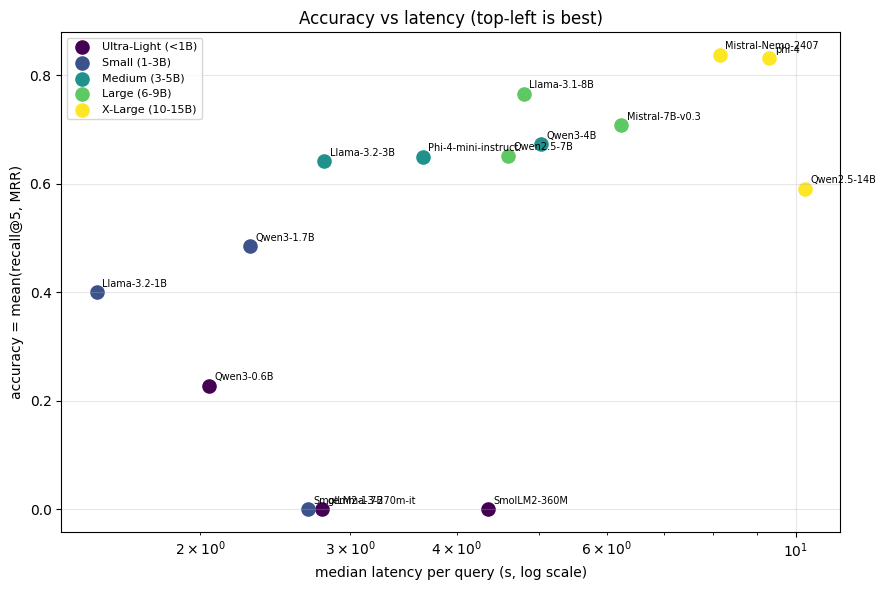

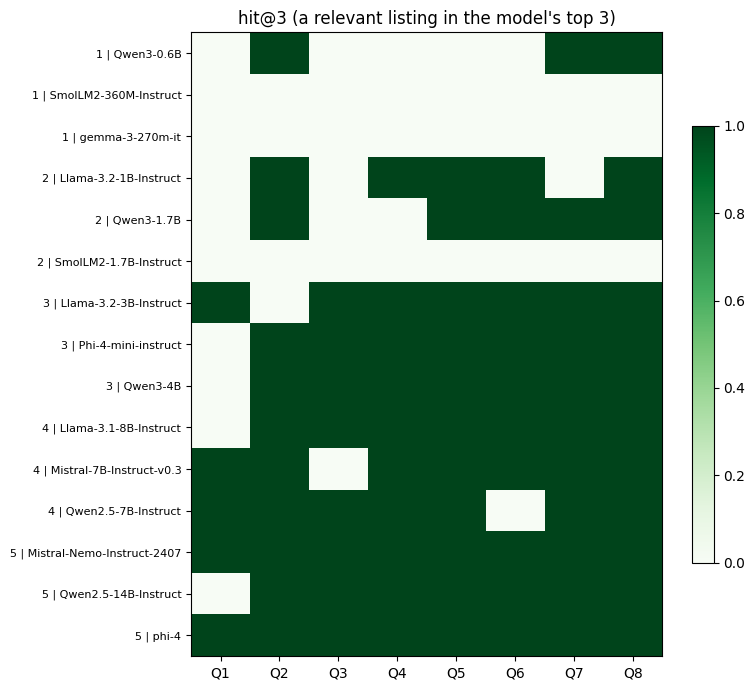

In [ ]:
import matplotlib.pyplot as plt

# 1) accuracy vs latency
fig, ax = plt.subplots(figsize=(9, 6))
cmap = plt.get_cmap("viridis", 5)
for c, grp in summary.groupby("category"):
    ax.scatter(grp["lat_med"], (grp["recall5"] + grp["mrr"]) / 2, s=90, color=cmap(c - 1), label=CATEGORIES[c])
    for _, r in grp.iterrows():
        ax.annotate(r["name"].replace("-Instruct", ""), (r["lat_med"], (r["recall5"] + r["mrr"]) / 2),
                    fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("median latency per query (s, log scale)")
ax.set_ylabel("accuracy = mean(recall@5, MRR)"); ax.set_title("Accuracy vs latency (top-left is best)")
ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "accuracy_vs_latency.png", dpi=150); plt.show()

# 2) model x query heatmap of hit@3
pv = df.pivot_table(index=["category", "name"], columns="query_id", values="hit3", aggfunc="mean")
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(pv.values, cmap="Greens", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(pv.shape[1])); ax.set_xticklabels([f"Q{q}" for q in pv.columns])
ax.set_yticks(range(pv.shape[0])); ax.set_yticklabels([f"{c} | {n}" for c, n in pv.index], fontsize=8)
ax.set_title("hit@3 (a relevant listing in the model's top 3)")
fig.colorbar(im, ax=ax, shrink=.7); fig.tight_layout()
fig.savefig(RESULTS_DIR / "hit3_heatmap.png", dpi=150); plt.show()

## 7. Top-3 selection

Composite score used to pick the 3 models handed to the next stage:

`composite = 0.7 x accuracy + 0.3 x latency_score`

* `accuracy = mean(recall@5, MRR)` averaged over the 8 queries (already 0-1)
* `latency_score` = 1 - min-max of **log** median latency across eligible models (fastest = 1, slowest = 0; log because latencies span ~100x)
* **Eligibility:** `valid_json` >= 0.8 **and** `complete5` >= 0.8 - a model that cannot reliably produce a usable top-5 list is useless for the app however clever its guesses.

A sensitivity check shows the ranking with accuracy only.

In [ ]:
ACC_W, LAT_W = 0.7, 0.3
s = summary.copy()
s["accuracy"] = (s["recall5"] + s["mrr"]) / 2
eligible = s[(s["valid_json"] >= 0.8) & (s["complete5"] >= 0.8)].copy()
if len(eligible) < 3:
    print(f"WARNING: only {len(eligible)} models passed the format filter - falling back to all {len(s)}")
    eligible = s.copy()
lo, hi = np.log(eligible["lat_med"]).min(), np.log(eligible["lat_med"]).max()
eligible["latency_score"] = 1 - (np.log(eligible["lat_med"]) - lo) / (hi - lo + 1e-9)
eligible["composite"] = ACC_W * eligible["accuracy"] + LAT_W * eligible["latency_score"]
ranked = eligible.sort_values("composite", ascending=False).reset_index(drop=True)
top3 = ranked.head(3)

print("Excluded for unreliable format:", sorted(set(s["name"]) - set(eligible["name"])) or "none")
display_cols = ["name", "category_name", "quant", "accuracy", "recall5", "mrr", "lat_med", "latency_score", "composite", "valid_json", "complete5"]
print("\n=== TOP 3 ===")
print(top3[display_cols].round(3).to_string(index=False))
print("\n=== full ranking ===")
print(ranked[display_cols].round(3).to_string(index=False))

acc_only = eligible.sort_values(["accuracy", "lat_med"], ascending=[False, True]).head(3)["name"].tolist()
print("\nSensitivity - top 3 by accuracy only:", acc_only)
print("Same set as the composite top 3?", set(acc_only) == set(top3["name"]))

Excluded for unreliable format: ['Llama-3.1-8B-Instruct', 'Llama-3.2-1B-Instruct', 'Qwen3-0.6B', 'SmolLM2-1.7B-Instruct', 'SmolLM2-360M-Instruct', 'gemma-3-270m-it']

=== TOP 3 ===
                 name category_name quant  accuracy  recall5   mrr  lat_med  latency_score  composite  valid_json  complete5
Llama-3.2-3B-Instruct Medium (3-5B)  fp16     0.642    0.508 0.775    2.797          0.865      0.709       1.000      0.875
  Phi-4-mini-instruct Medium (3-5B)  fp16     0.650    0.519 0.781    3.651          0.688      0.661       1.000      0.875
           Qwen3-1.7B  Small (1-3B)  fp16     0.485    0.408 0.562    2.285          1.000      0.640       0.875      1.000

=== full ranking ===
                      name    category_name quant  accuracy  recall5   mrr  lat_med  latency_score  composite  valid_json  complete5
     Llama-3.2-3B-Instruct    Medium (3-5B)  fp16     0.642    0.508 0.775    2.797          0.865      0.709       1.000      0.875
       Phi-4-mini-instruct    M

In [ ]:
# Hand-off for the prompt-engineering stage
export = []
for _, r in top3.iterrows():
    spec = next(m for m in MODELS if m["id"] == r["id"])
    export.append({"id": spec["id"], "name": spec["name"], "category": CATEGORIES[spec["category"]],
                   "params_b": spec["params_b"], "quant": spec["quant"], "dtype": spec["dtype"],
                   "gated": spec["gated"], "template_kwargs": spec["template_kwargs"],
                   "scores": {k: round(float(r[k]), 4) for k in
                              ["accuracy", "recall5", "mrr", "hit1", "hit3", "ndcg5", "precision",
                               "valid_json", "complete5", "lat_med", "lat_p95", "tok_s", "composite"]}})
(RESULTS_DIR / "top3_models.json").write_text(json.dumps(export, indent=2))
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
df.drop(columns=["raw_output"]).to_csv(RESULTS_DIR / "results.csv", index=False)
print("saved results/top3_models.json, summary.csv, results.csv, charts")

# To re-run only the top-3 with another prompt style, reuse the harness above, e.g.:
#   run_matrix([m for m in MODELS if m["id"] in {e["id"] for e in export}],
#              variant="one_shot", examples=[(GOLD[4]["query"], GOLD[4]["relevant"][:5])])
export

saved results/top3_models.json, summary.csv, results.csv, charts


[{'id': 'meta-llama/Llama-3.2-3B-Instruct',
  'name': 'Llama-3.2-3B-Instruct',
  'category': 'Medium (3-5B)',
  'params_b': 3.21,
  'quant': 'fp16',
  'dtype': 'float16',
  'gated': True,
  'template_kwargs': {},
  'scores': {'accuracy': 0.6417,
   'recall5': 0.5083,
   'mrr': 0.775,
   'hit1': 0.625,
   'hit3': 0.875,
   'ndcg5': 0.5059,
   'precision': 0.3917,
   'valid_json': 1.0,
   'complete5': 0.875,
   'lat_med': 2.7969,
   'lat_p95': 2.8186,
   'tok_s': 6.7952,
   'composite': 0.7088}},
 {'id': 'microsoft/Phi-4-mini-instruct',
  'name': 'Phi-4-mini-instruct',
  'category': 'Medium (3-5B)',
  'params_b': 3.84,
  'quant': 'fp16',
  'dtype': 'float16',
  'gated': False,
  'template_kwargs': {},
  'scores': {'accuracy': 0.65,
   'recall5': 0.5188,
   'mrr': 0.7812,
   'hit1': 0.625,
   'hit3': 0.875,
   'ndcg5': 0.5123,
   'precision': 0.4125,
   'valid_json': 1.0,
   'complete5': 0.875,
   'lat_med': 3.6512,
   'lat_p95': 3.6612,
   'tok_s': 7.1282,
   'composite': 0.6614}},
 {'id

## 8. Findings

All 15 models ran in a single Colab session (T4 GPU), 8 queries each, greedy decoding. Figures below are means over the 8 queries from the Results and Top-3 sections above.

**Best model per category** (recall@5, ties broken by MRR)

| Category | Best model | recall@5 | MRR | median latency |
|---|---|---|---|---|
| 1. Ultra-Light (<1B) | Qwen3-0.6B | 0.16 | 0.29 | 2.0 s |
| 2. Small (1-3B) | Qwen3-1.7B | 0.41 | 0.56 | 2.3 s |
| 3. Medium (3-5B) | Qwen3-4B | 0.66 | 0.69 | 5.0 s |
| 4. Large (6-9B) | Llama-3.1-8B-Instruct | 0.72 | 0.81 | 4.8 s |
| 5. X-Large (10-15B) | phi-4 | 0.85 | 0.81 | 9.3 s |

**Top 3 overall** (composite = 0.7 x accuracy + 0.3 x latency score, format filter applied): Llama-3.2-3B-Instruct (0.709), Phi-4-mini-instruct (0.661), Qwen3-1.7B (0.640). The composite rewards speed, so it favours small, fast models. Ranked by accuracy alone the top 3 would be Mistral-Nemo-12B, phi-4 and Mistral-7B-v0.3, so the two rankings do not agree and the choice depends on how much latency matters.

**Accuracy and size:** quality rises with size. The 12-14B models reach recall@5 of 0.80-0.85 (Mistral-Nemo 0.80, phi-4 0.85) against 0.51-0.66 for the 3-4B models and 0.16 or lower for the sub-1B models. Latency rises too, from about 2 s to 8-10 s per query. Size is not a guarantee: Qwen2.5-14B (recall@5 0.54) scored below the 7B Mistral (0.72).

**Format reliability:** 6 of 15 models were excluded from the top-3 ranking for failing the format filter (valid JSON and a complete 5-id list on at least 80% of queries). gemma-3-270m-it, SmolLM2-360M-Instruct and SmolLM2-1.7B-Instruct never produced valid ids (recall 0.0). Llama-3.2-1B-Instruct gave valid JSON on only 12% of queries, Qwen3-0.6B on 75%, and Llama-3.1-8B-Instruct returned a complete top 5 on 75% of queries. Llama-3.1-8B is the best category-4 model by recall but misses the reliability bar. Hallucinated ids were rare (at most about 0.2 per query on average).

**Failure modes seen in the output:** the smallest models ignore the request and return generic items. For the living-room decor query, Qwen3-0.6B returned a rocking chair, nightstand, rugs and a microwave, and Llama-3.2-1B returned a kitchen utensil set, bookshelf and microwave, none of the gold decor items. See the per-model outputs for queries 1 and 2 above for the rest.

**Caveats:** categories 4-5 ran in 4-bit (NF4), so their latency is not strictly comparable with the 16-bit models. Results come from one greedy run on 8 queries and a 40-listing catalogue, so small differences between models are not significant.